In [66]:
import numpy as np
import matplotlib.pyplot as plt
from week05 import make_microstate_factory
from scipy.spatial.distance import pdist
from math import comb

{np.float64(-0.5): np.int64(12), np.float64(-0.25): np.int64(8), np.float64(0.0): np.int64(16)}


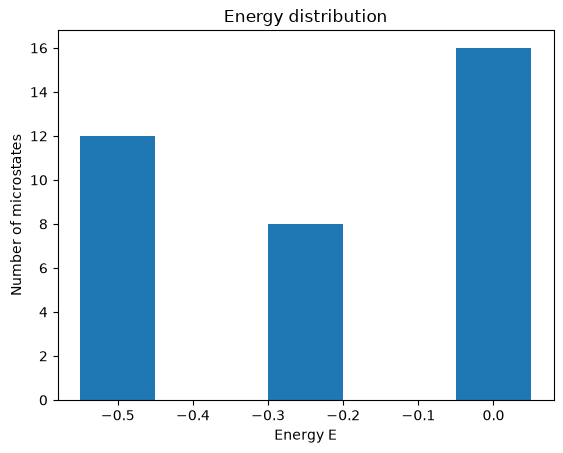

-0.393710625088529


In [67]:
L = 3
sites = [(x, y) for x in range(L) for y in range(L)]

d2 = pdist(sites, "sqeuclidean")     

E = np.zeros(len(d2))
E[d2 == 1] = -0.5                 
E[d2 == 2] = -0.25                   

vals, counts = np.unique(E, return_counts=True)
print(dict(zip(vals, counts)))      

plt.bar(vals, counts, width=0.1)
plt.xlabel("Energy E")
plt.ylabel("Number of microstates")
plt.title("Energy distribution")
plt.show()

# canonical average
def avg_E(kT, E):
    w = np.exp(-E / kT)
    return (E * w).sum() / w.sum()

print(avg_E(0.25, E))                

36
0 -0.5
1 -0.0
2 -0.5
31 -0.25


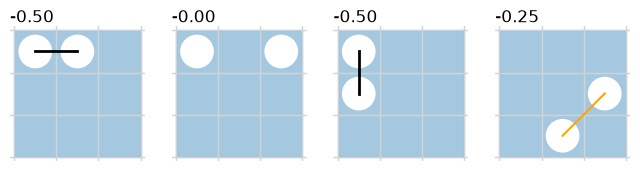

In [68]:
MicroState = make_microstate_factory(N=2, L=3)
print(MicroState.total) 

indices = [0, 1, 2, 31]
fig, axes = plt.subplots(1, len(indices), figsize=(8, 2.5))
for ax, i in zip(axes, indices):
    m = MicroState(i)
    m.plot(ax, label='Energy')
    print(i, m.energy)

nan


/tmp/ipykernel_24195/3761535986.py:21: RuntimeWarning: divide by zero encountered in divide
  w = np.exp(-E / kT)
/tmp/ipykernel_24195/3761535986.py:22: RuntimeWarning: invalid value encountered in scalar divide
  return (E * w).sum() / w.sum()


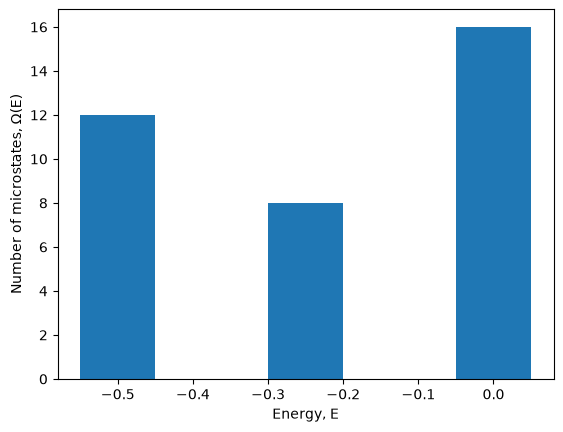

In [69]:
Es = []
for i in range(MicroState.total):
    m = MicroState(i)
    Es.append(m.energy)
E = np.array(Es)

vals, counts = np.unique(E, return_counts=True)
#print(dict(zip(vals, counts)))

print(avg_E(E, 0.25))            # compare with your Task 1 value, about -0.394

plt.bar(vals, counts, width=0.1)
plt.xlabel("Energy, E")
plt.ylabel("Number of microstates, Ω(E)")
plt.show()

58905
58905


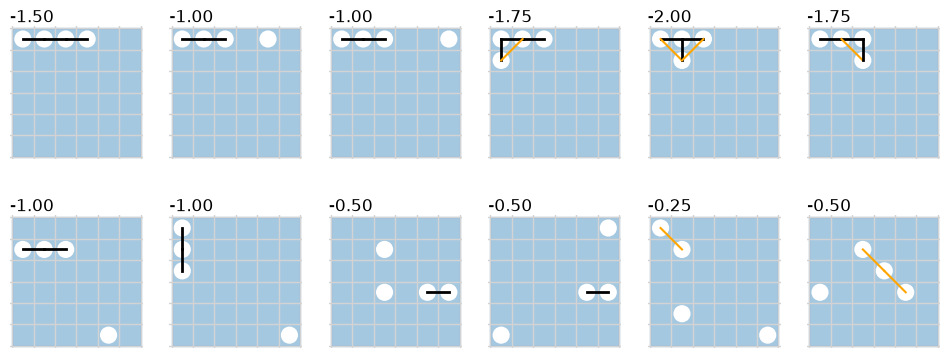

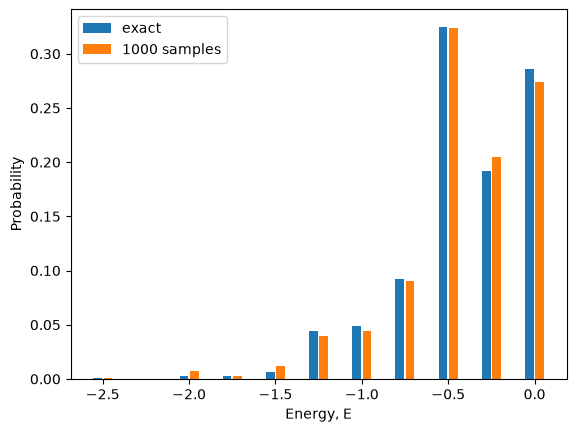

In [70]:
N = 4 # atoms
L = 6 # LxL grid

MicroState = make_microstate_factory(N=4, L=6)
print(MicroState.total)
MicroState_total_binomial = comb(L**2, N)
print(MicroState_total_binomial)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for k in range(6):
    m = MicroState(k)
    m.plot(axes[0, k], label='Energy')
for k in range(6):
    m = MicroState()                      # random microstate
    m.plot(axes[1, k], label='Energy')
plt.show()

E_all = np.array([MicroState(i).energy for i in range(MicroState.total)])
vals_all, counts_all = np.unique(E_all, return_counts=True)

# 4. Sampled histogram: draw random microstates
n_samples = 1000
E_sample = np.array([MicroState().energy for _ in range(n_samples)])
vals_s, counts_s = np.unique(E_sample, return_counts=True)

plt.bar(vals_all - 0.03, counts_all / counts_all.sum(), width=0.05, label="exact")
plt.bar(vals_s + 0.03, counts_s / counts_s.sum(), width=0.05, label=f"{n_samples} samples")
plt.xlabel("Energy, E")
plt.ylabel("Probability")
plt.legend()
plt.show()

58905
58905


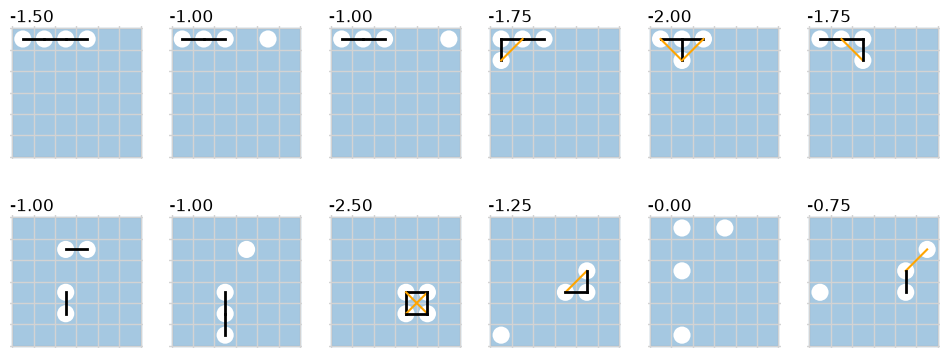

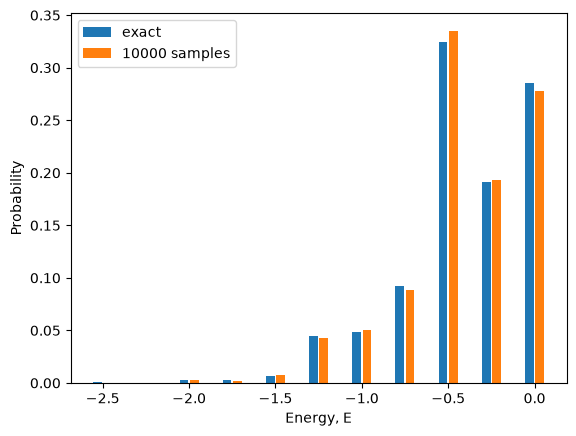

In [71]:
N = 4 # atoms
L = 6 # LxL grid

MicroState = make_microstate_factory(N=4, L=6)
print(MicroState.total)
MicroState_total_binomial = comb(L**2, N)
print(MicroState_total_binomial)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for k in range(6):
    m = MicroState(k)
    m.plot(axes[0, k], label='Energy')
for k in range(6):
    m = MicroState()                      # random microstate
    m.plot(axes[1, k], label='Energy')
plt.show()

E_all = np.array([MicroState(i).energy for i in range(MicroState.total)])
vals_all, counts_all = np.unique(E_all, return_counts=True)

# 4. Sampled histogram: draw random microstates
n_samples = 10000
E_sample = np.array([MicroState().energy for _ in range(n_samples)])
vals_s, counts_s = np.unique(E_sample, return_counts=True)

plt.bar(vals_all - 0.03, counts_all / counts_all.sum(), width=0.05, label="exact")
plt.bar(vals_s + 0.03, counts_s / counts_s.sum(), width=0.05, label=f"{n_samples} samples")
plt.xlabel("Energy, E")
plt.ylabel("Probability")
plt.legend()
plt.show()

In [72]:
E0_exact = avg_E(.33, E_all)
print("exact:", E0_exact)
for n in [1000, 10000, 100000]:
    E_s = np.array([MicroState().energy for _ in range(n)])
    print(n, avg_E(.33, E_s))

exact: -1.22404575616458
1000 -1.0433112723338471
10000 -1.180717457149803
100000 -1.2469621569890192


/tmp/ipykernel_24195/4194622597.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].set_xlabel("Energy"); ax.set_ylabel("Entropy"); ax.legend()


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

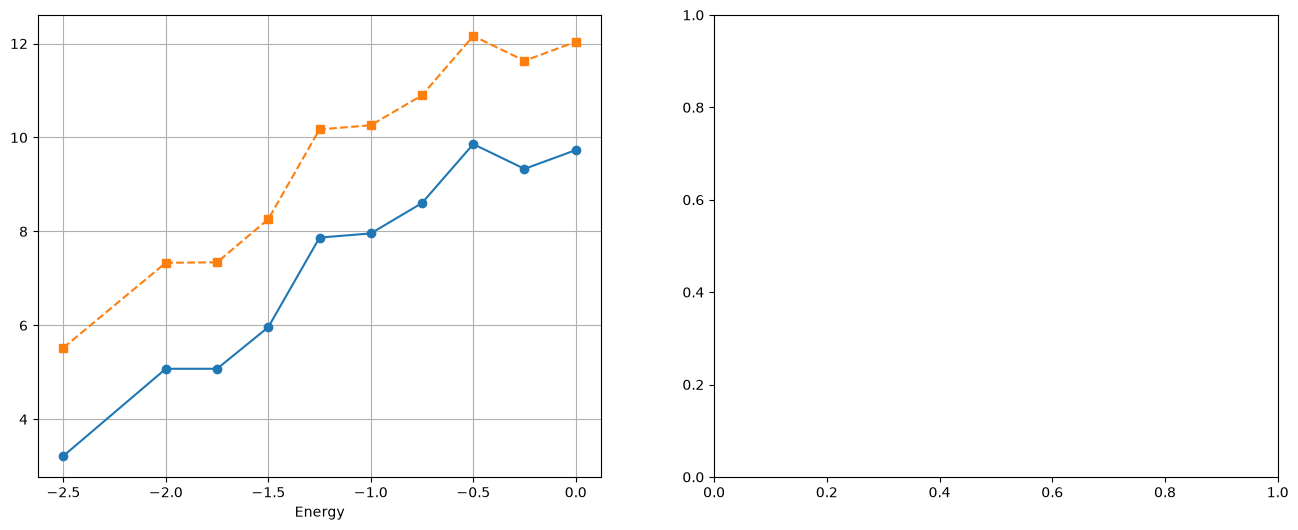

In [73]:
n_samples = 58905*10
E_sample = np.array([MicroState().energy for _ in range(n_samples)])

def histogram(E, dE=.25):
    k = np.round(E/dE).astype(int)
    ks, counts = np.unique(k, return_counts=True)
    return ks*dE, counts


E_bins, Omega = histogram(E_all)
E_bins_s, n = histogram(E_sample)

S = np.log(Omega) # entropy
lnn = np.log(n)   # n(E) is prop to Omega(E)

fig, axes = plt.subplots(1,2, figsize=(16,6))
axes[0].plot(E_bins, S,  '-o', label=r'$\ln\Omega(E)$ (enumeration)')
axes[0].plot(E_bins_s, lnn, 's--', label=r'$\ln n(E)$ (sampled)')
axes[0].set_xlabel("Energy"); ax.set_ylabel("Entropy"); ax.legend()
axes[0].grid()

def temperature(E_bins, S):
    dSdE = np.gradient(S, E_bins)                  
    return 1.0 / dSdE

T = temperature(E_bins, S)
T_s = temperature(E_bins_s, lnn)

axes[1].plot(E_bins[m], T[m], 'o-', label="enumeration")
axes[1].plot(E_bins_s[ms], T_s[ms], 's--', label="sampled")
axes[1].plot(E0_exact, 0.33, 'k+', markersize=15)      # cross-hair (E0, T)
axes[1].set_xlabel("Energy"); axes[1].set_ylabel("T(E)"); axes[1].legend()
axes[1].grid()

In [ ]:
N = 6 # atoms
L = 8 # LxL grid

MicroState = make_microstate_factory(N=N, L=L)
E_all = np.array([MicroState(i).energy for i in range(MicroState.total)])

E_bins, Omega = histogram(E_all)
E_bins_s, n = histogram(E_sample)

S = np.log(Omega) # entropy
lnn = np.log(n)   # n(E) is prop to Omega(E)

fig, axes = plt.subplots(1,2, figsize=(16,6))
axes[0].plot(E_bins, S,  '-o', label=r'$\ln\Omega(E)$ (enumeration)')
axes[0].plot(E_bins_s, lnn, 's--', label=r'$\ln n(E)$ (sampled)')
axes[0].set_xlabel("Energy"); ax.set_ylabel("Entropy"); ax.legend()
axes[0].grid()

T = temperature(E_bins, S)
T_s = temperature(E_bins_s, lnn)

axes[1].plot(E_bins[m], T[m], 'o-', label="enumeration")
axes[1].plot(E_bins_s[ms], T_s[ms], 's--', label="sampled")
axes[1].plot(E0_exact, 0.33, 'k+', markersize=15)      # cross-hair (E0, T)
axes[1].set_xlabel("Energy"); axes[1].set_ylabel("T(E)"); axes[1].legend()
axes[1].grid()

KeyboardInterrupt: 

/tmp/ipykernel_24195/4194622597.py:24: RuntimeWarning: divide by zero encountered in divide
  return 1.0 / dSdE


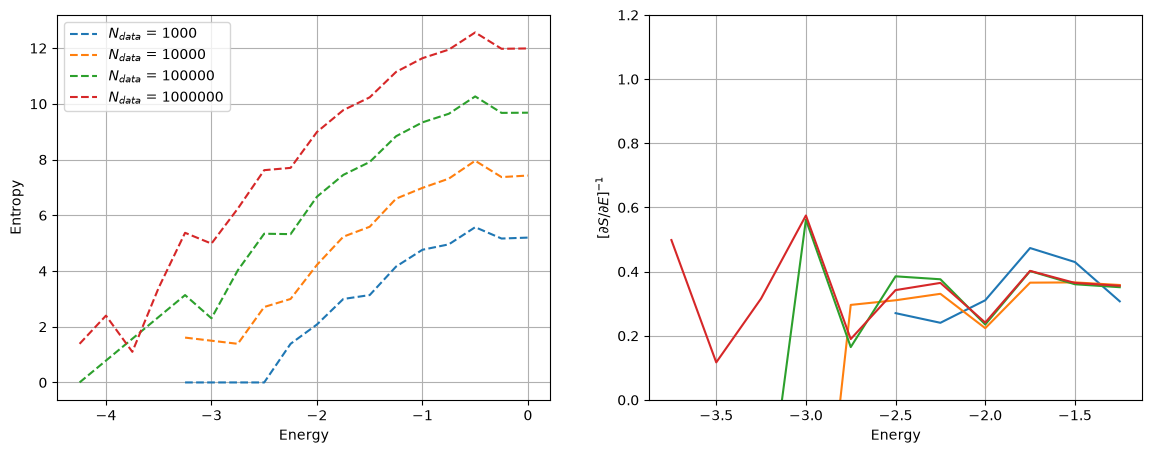

In [75]:
N = 6  # atoms
L = 8  # LxL grid

MicroState = make_microstate_factory(N=N, L=L)

sizes = [1_000, 10_000, 100_000, 1_000_000]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for N_data in sizes:
    E = np.array([MicroState().energy for _ in range(N_data)])
    E_bins, n = histogram(E)
    lnn = np.log(n)
    T = temperature(E_bins, lnn)
    line, = axes[0].plot(E_bins, lnn, '--', label=f"$N_{{data}}$ = {N_data}")

    m = (E_bins > -4.0) & (E_bins < -1.0)                  # change 1: energy window
    axes[1].plot(E_bins[m], T[m], color=line.get_color())

axes[0].set_xlabel("Energy"); axes[0].set_ylabel("Entropy")
axes[0].legend(); axes[0].grid()
axes[1].set_xlabel("Energy"); axes[1].set_ylabel(r"$[\partial S/\partial E]^{-1}$")
axes[1].set_ylim(0, 1.2)                                   # change 2: y-range
axes[1].grid()
plt.show()